# Cookie Cats A/B Testi - 4. Güç Analizi

retention_1'de fark anlamlı çıkmadı. Bunun sebebi gerçekten fark olmaması mı, yoksa deneyin bu farkı görecek kadar büyük olmaması mı? Bunu anlamak için güç analizi yaptım.

- **Güç (power):** gerçek bir fark varsa testin onu yakalama olasılığı (hedef %80).
- **MDE:** deneyin %80 güçle yakalayabileceği en küçük fark.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/cookie_cats_clean.csv")
n30 = (df["version"] == "gate_30").sum()
n40 = (df["version"] == "gate_40").sum()
base = df[df["version"] == "gate_30"][["retention_1", "retention_7"]].mean()
observed = {"retention_7": 0.008183, "retention_1": 0.005915}   # 3. notebook'taki farklar
z_a, z_b = norm.ppf(0.975), norm.ppf(0.80)

## MDE

In [2]:
def se(p):
    return np.sqrt(p * (1 - p) * (1 / n30 + 1 / n40))

for col in ["retention_7", "retention_1"]:
    mde = (z_a + z_b) * se(base[col])
    print(f"{col}: MDE = {mde*100:.2f} puan (göreli {mde/base[col]*100:.1f}%), gözlenen fark = {observed[col]*100:.2f} puan")

retention_7: MDE = 0.73 puan (göreli 3.9%), gözlenen fark = 0.82 puan
retention_1: MDE = 0.93 puan (göreli 2.1%), gözlenen fark = 0.59 puan


- retention_7: gözlenen fark (0.82) MDE'nin (0.73) üstünde, deney bu fark için yeterli.
- retention_1: gözlenen fark (0.59) MDE'nin (0.93) altında. Yani deney bu kadar küçük bir farkı güvenilir şekilde görecek kadar büyük değil.

## Güç eğrisi

retention_7: gözlenen farkta güç = 88%
retention_1: gözlenen farkta güç = 43%


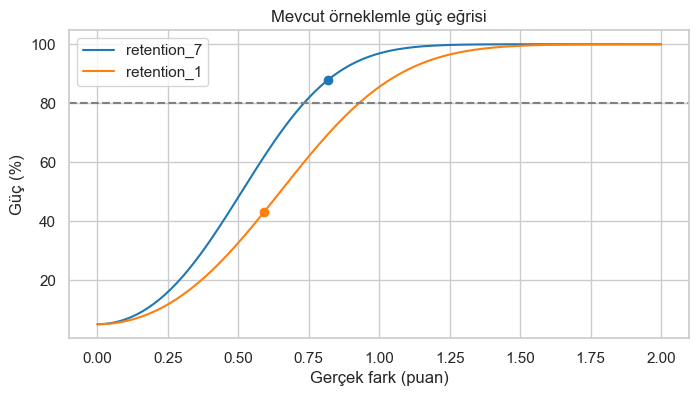

In [3]:
def power(diff, p):
    return norm.cdf(diff / se(p) - z_a) + norm.cdf(-diff / se(p) - z_a)

d = np.linspace(0, 0.02, 200)
plt.figure(figsize=(8, 4))
for col, c in [("retention_7", "tab:blue"), ("retention_1", "tab:orange")]:
    plt.plot(d * 100, power(d, base[col]) * 100, label=col, color=c)
    pw = power(observed[col], base[col])
    plt.scatter(observed[col] * 100, pw * 100, color=c, zorder=3)
    print(f"{col}: gözlenen farkta güç = {pw*100:.0f}%")
plt.axhline(80, color="gray", linestyle="--")
plt.xlabel("Gerçek fark (puan)")
plt.ylabel("Güç (%)")
plt.title("Mevcut örneklemle güç eğrisi")
plt.legend()
plt.savefig("../figures/07_guc_egrisi.png", dpi=120, bbox_inches="tight")
plt.show()

Gözlenen farklar için güç: retention_7'de %88, retention_1'de sadece %43. (Gözlenen farkla hesaplanan güç sadece referans için, asıl karşılaştırmayı MDE ile yaptım.)

## Gereken örneklem büyüklüğü

In [4]:
analysis = NormalIndPower()
rows = []
for col in ["retention_7", "retention_1"]:
    for diff in [observed[col], 0.005, 0.01]:
        h = proportion_effectsize(base[col], base[col] - diff)
        n = analysis.solve_power(effect_size=h, alpha=0.05, power=0.8)
        rows.append([col, round(diff * 100, 2), int(np.ceil(n))])
pd.DataFrame(rows, columns=["metrik", "fark_puan", "grup_basina_gereken_n"])

,metrik,fark_puan,grup_basina_gereken_n
0,retention_7,0.82,35504
1,retention_7,0.50,95727
2,retention_7,1.00,23683
3,retention_1,0.59,110821
4,retention_1,0.50,155125
5,retention_1,1.00,38737


retention_1'deki 0.59 puanlık farkı yakalamak için grup başına yaklaşık 111 bin oyuncu gerekirdi, elimizde yaklaşık 45 bin var (2.5 katı lazım). Bu yüzden retention_1 için "etki yok" diyemem, sadece "bu deneyle tespit edilemedi" diyebilirim.

## Simülasyon ile kontrol

Formülleri kontrol etmek için 2.000 sahte deney ürettim. Gerçek fark 0 iken testlerin yaklaşık %5'i anlamlı çıkmalı (α = 0.05, yanlış alarm oranı). Gerçek fark gözlenen fark kadarken anlamlı çıkma oranı güce eşit olmalı.

In [5]:
rng = np.random.default_rng(7)

def simulate(p, diff, n_sim=2000):
    x1 = rng.binomial(n30, p, n_sim)
    x2 = rng.binomial(n40, p - diff, n_sim)
    p_values = [proportions_ztest([i, j], [n30, n40])[1] for i, j in zip(x1, x2)]
    return np.mean(np.array(p_values) < 0.05)

for col in ["retention_7", "retention_1"]:
    print(col, "| fark yok:", simulate(base[col], 0), "| gözlenen fark:", simulate(base[col], observed[col]))

retention_7 | fark yok: 0.0485 | gözlenen fark: 0.8855


retention_1 | fark yok: 0.049 | gözlenen fark: 0.447


Simülasyon sonuçları formüllerle uyumlu: fark yokken yaklaşık %5 yanlış alarm, gözlenen farklarda yaklaşık %88 ve %45 güç.

## Özet
- Deney retention_7'de 0.73 puan ve üzeri farkları %80 güçle yakalayabiliyor. Gözlenen fark 0.82, yani sonuç güvenilir.
- retention_1'de MDE 0.93 puan, gözlenen fark 0.59. Anlamlı çıkmaması "etki yok" demek değil, örneklem yetersiz.
- Yeni bir deneyde önce önemli olan en küçük farkı belirleyip örneklem büyüklüğünü ona göre hesaplamak gerekir.